## Processing of the environmental drivers
- SST
- Variability of SST (temporal standard deviation of the daily sea surface temperature in each grid
cell)
- Chlorophyll-a
- Eddy kinetic Energy = (1/2) * (ugosa^2 + vgosa^2)

In [10]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import rioxarray

variable = "sst"
period = "2017_2019"
variability = True


ds = xr.load_dataset(f"data/raw/driver_data/environmental/{variable}_{period}.nc")
if variable == "sst" and variability:
    da_mean = ds[variable].std(dim="time", skipna=True, ddof=1)
else:
    da_mean = ds[variable].mean(dim="time", skipna=True)
da_mean.data

if variable == "chl":
    da_mean = np.log10(da_mean)


da_mean.max

/home/yolanda/Documents/GIT_ProjectSeminar/AIS-disabling-analysis/.venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


<bound method DataArrayAggregations.max of <xarray.DataArray 'sst' (latitude: 819, longitude: 1387)> Size: 9MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(819, 1387))
Coordinates:
  * latitude   (latitude) float64 7kB -80.0 -79.8 -79.6 -79.4 ... 83.2 83.4 83.6
  * longitude  (longitude) float64 11kB -179.9 -179.6 -179.4 ... 179.4 179.6
Attributes:
    long_name:      Sea Surface Temperature
    regrid_method:  bilinear
    standard_name:  sea_surface_temperature
    units:          Celsius>

In [11]:
print(da_mean.min().values, da_mean.max().values)

0.0008212195151427522 12.036665945536834


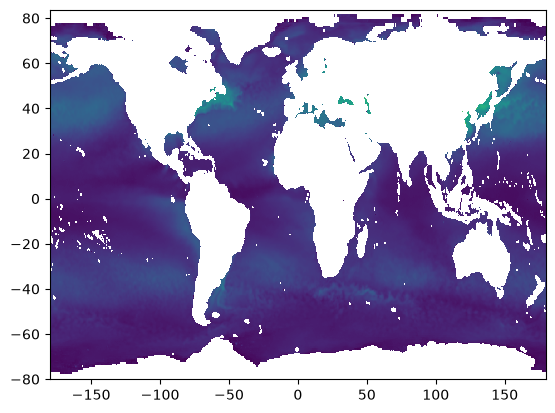

In [12]:
lat = ds[variable].latitude.data  # numpy array
lon = ds[variable].longitude.data  # numpy array

plt.figure()
plt.pcolormesh(lon, lat, da_mean.data[:,:]); # shape (1,n,m)

In [13]:
# CRS setzen (WGS84, da lat/lon)
raster = da_mean.rio.write_crs("EPSG:4326")[:,:]

# Als GeoTIFF speichern
raster.rio.to_raster(f"data/processed/variability_{variable}_{period}.tif")

In [6]:
# Eddy kinetic Energy
period = "2023_2025"

da_ugosa = xr.open_dataset(
    f"data/raw/driver_data/environmental/ugosa_{period}.nc",
    chunks={"time": 50}  # process in chunks along time, not all at once
).ugosa

da_vgosa = xr.open_dataset(
    f"data/raw/driver_data/environmental/vgosa_{period}.nc",
    chunks={"time": 50}
).vgosa

da_eddy = 0.5 * (da_ugosa**2 + da_vgosa**2)  # still lazy, nothing computed yet

eke_mean = da_eddy.mean(dim="time", skipna=True)  # triggers computation, but chunked/streamed
eke_mean = eke_mean.compute()  # or .load() to materialize the final (small) result

In [7]:
eke_mean

<xarray.DataArray (latitude: 720, longitude: 1440)> Size: 8MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(720, 1440))
Coordinates:
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9
Attributes:
    comment:       The geostrophic velocity anomalies are referenced to the [...
    grid_mapping:  crs
    units:         m/s

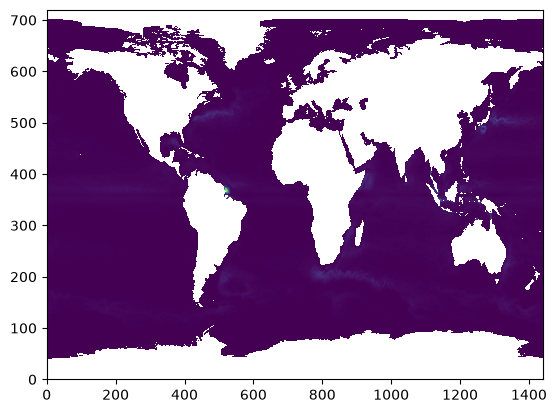

In [8]:
plt.figure()
plt.pcolormesh(eke_mean.data[:,:]); 

In [ ]:
# CRS setzen
raster = eke_mean.rio.write_crs("EPSG:4326")[:,:]

# Als tif speichern
raster.rio.to_raster(f"data/processed/eke_{period}.tif")